In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
from src.ExperimentSet import ExperimentSet
from src.Retrieval import Retrieval

In [3]:
EXPERIMENT_SET = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V09'
V08 = ExperimentSet(EXPERIMENT_SET)
V08.set_retrieval_list()
V08.load_retrievals(iteration=-1)

In [4]:
brf_ths = {
    'DF': 0.120,
    'CF': 0.076,
    'BF': 0.054,
    'AF': 0.044,
    'AN': 0.040,
    'AA': 0.045,
    'BA': 0.052,
    'CA': 0.068,
    'DA': 0.092
}
for rpath in V08.retrievals:
    r = V08.retrievals[rpath]
    r.add_threshold_mask(r.obs, 'MISR', 'threshold_mask', 'brf', brf_ths)

In [5]:
def misr_S_1(y):
    return np.diag(1 / (0.04 * y)**2)
mask_conds = {
    # 'tau0.3mask': (1, 1),
    'threshold_mask': (1, 1),
    'ray_containment': (2, 2)
}
chi2 = V08.chi2(misr_S_1, variable='I', mask_conds=mask_conds)
chi2

,chi2
retrieval,
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/default,8.984105
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/0p150,7.887847
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/0p250,13.206345
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/mix22,8.790481
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/mix54,9.914643
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/fast,11.936640
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/fast_unconstrained,14.999378
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/slow,12.219415
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/slow_unconstrained,10.997282


In [10]:
ext_th = [0.3, np.inf]
tau_th = [0.3, np.inf]
stats = V08.cloud_stats(0.67, 'cloud')
ref_key = Path('/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/default')
compare = V08.compare_to(ref_key, 0.67, 'cloud', extinction_th=ext_th, tau_th=tau_th)
table = pd.merge(compare, stats, on='retrieval')
table = pd.merge(table, chi2, on='retrieval')

ext_th_all = [0, np.inf]
tau_th_all = [0, np.inf]
stats_all = V08.cloud_stats(0.67, 'cloud')
ref_key = Path('/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/default')
compare_all = V08.compare_to(ref_key, 0.67, 'cloud', extinction_th=ext_th_all, tau_th=tau_th_all)
table_all = pd.merge(compare_all, stats_all, on='retrieval')
table_all = pd.merge(table_all, chi2, on='retrieval')

In [11]:
table

,relative bias,relative difference,cloud fraction,tau bar,volume,cloudy voxel count,min extinction,q5,q25,q50,q75,q95,max extinction,mean extinction,std extinction,chi2
retrieval,,,,,,,,,,,,,,,,
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/default,0.000000,0.000000,0.3221301775147929,1.2238734339238353,23.852125000000004,3154,5.734876e-05,0.085304,0.855607,2.647811,6.929220,19.600517,55.747046,5.281204,6.810679,8.984105
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/0p150,13.905926,0.431211,0.5171597633136095,0.8873728223246901,36.0504375,4767,4.987880e-15,0.031726,0.490011,1.595740,4.864753,16.838809,61.152506,4.067358,6.184169,7.887847
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/0p250,-6.375499,1.869878,0.22958579881656804,1.5807873986455063,13.801562500000003,1825,1.018287e-03,0.162490,1.161702,4.030470,11.396263,31.438100,104.265077,8.401993,11.073714,13.206345
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/mix22,0.908616,0.421282,0.3315976331360947,1.1992607765123167,26.46875000000001,3500,1.173096e-08,0.034283,0.577480,2.410541,6.526225,18.219870,47.678334,4.800470,6.271410,8.790481
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/mix54,-4.498526,1.054245,0.27928994082840236,1.3393637643133578,19.443187500000008,2571,6.842123e-09,0.028389,0.727972,2.667611,8.070327,24.358681,78.236337,6.147216,8.660152,9.914643
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/fast,-0.222438,1.685644,0.34437869822485206,1.1440594507139663,25.51587500000001,3374,2.383564e-09,0.049002,0.833373,2.772972,7.034126,16.736514,41.932180,4.933629,5.777817,11.936640
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/fast_unconstrained,24.544685,3.063526,0.43715976331360945,1.0375102266581697,39.24559375000001,5754,2.274040e-07,0.014612,0.403434,1.595303,4.808814,14.659974,62.715337,3.732618,5.449731,14.999378
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/slow,0.393837,1.728475,0.3604733727810651,1.1077431912401503,21.598500000000005,2856,1.064873e-05,0.066292,0.772323,2.596763,7.443635,23.266621,77.233358,5.907188,8.584222,12.219415
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/slow_unconstrained,29.554078,3.273388,0.4198816568047337,1.130207927382283,42.073968750000006,6177,2.110605e-09,0.028295,0.512251,1.725550,4.800221,13.929325,42.390568,3.610870,4.808741,10.997282


In [12]:
table_all

,relative bias,relative difference,cloud fraction,tau bar,volume,cloudy voxel count,min extinction,q5,q25,q50,q75,q95,max extinction,mean extinction,std extinction,chi2
retrieval,,,,,,,,,,,,,,,,
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/default,0.000000,0.000000,0.3221301775147929,1.2238734339238353,23.852125000000004,3154,5.734876e-05,0.085304,0.855607,2.647811,6.929220,19.600517,55.747046,5.281204,6.810679,8.984105
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/0p150,16.402667,0.379314,0.5171597633136095,0.8873728223246901,36.0504375,4767,4.987880e-15,0.031726,0.490011,1.595740,4.864753,16.838809,61.152506,4.067358,6.184169,7.887847
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/0p250,-7.944325,1.786173,0.22958579881656804,1.5807873986455063,13.801562500000003,1825,1.018287e-03,0.162490,1.161702,4.030470,11.396263,31.438100,104.265077,8.401993,11.073714,13.206345
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/mix22,0.868865,0.390064,0.3315976331360947,1.1992607765123167,26.46875000000001,3500,1.173096e-08,0.034283,0.577480,2.410541,6.526225,18.219870,47.678334,4.800470,6.271410,8.790481
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/mix54,-5.117544,0.999846,0.27928994082840236,1.3393637643133578,19.443187500000008,2571,6.842123e-09,0.028389,0.727972,2.667611,8.070327,24.358681,78.236337,6.147216,8.660152,9.914643
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/fast,-0.065153,1.612117,0.34437869822485206,1.1440594507139663,25.51587500000001,3374,2.383564e-09,0.049002,0.833373,2.772972,7.034126,16.736514,41.932180,4.933629,5.777817,11.936640
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/fast_unconstrained,28.940332,2.959929,0.43715976331360945,1.0375102266581697,39.24559375000001,5754,2.274040e-07,0.014612,0.403434,1.595303,4.808814,14.659974,62.715337,3.732618,5.449731,14.999378
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/slow,1.284820,1.653273,0.3604733727810651,1.1077431912401503,21.598500000000005,2856,1.064873e-05,0.066292,0.772323,2.596763,7.443635,23.266621,77.233358,5.907188,8.584222,12.219415
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/slow_unconstrained,33.904389,3.162456,0.4198816568047337,1.130207927382283,42.073968750000006,6177,2.110605e-09,0.028295,0.512251,1.725550,4.800221,13.929325,42.390568,3.610870,4.808741,10.997282


In [13]:
table_all - table

,relative bias,relative difference,cloud fraction,tau bar,volume,cloudy voxel count,min extinction,q5,q25,q50,q75,q95,max extinction,mean extinction,std extinction,chi2
retrieval,,,,,,,,,,,,,,,,
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/default,0.000000,0.000000,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/0p150,2.496742,-0.051898,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/0p250,-1.568826,-0.083705,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/mix22,-0.039751,-0.031218,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/aerosol/mix54,-0.619018,-0.054399,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/fast,0.157285,-0.073527,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/fast_unconstrained,4.395647,-0.103597,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/slow,0.890983,-0.075202,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V09/cloud_motion/slow_unconstrained,4.350311,-0.110931,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


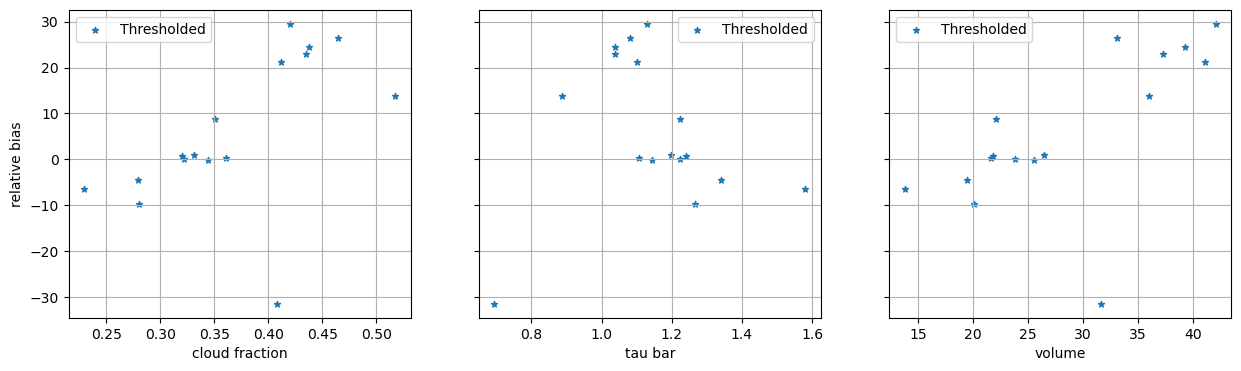

In [14]:
f, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
x = ['cloud fraction', 'tau bar', 'volume']
for i, a in enumerate(ax.flatten()):
    table.plot.scatter(x=x[i], y='relative bias', ax=a, marker='*', label='Thresholded')
    # table_all.plot.scatter(x=x[i], y='relative bias', ax=a, label='All')
    a.grid()
    a.legend()

# Threshold analysis

In [ ]:
r = Retrieval(PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'default')
r.load_retrieval()

In [ ]:
ext_ths = np.linspace(0, 1, 21)
tau_ths = np.linspace(0, 1, 21)
volume = np.zeros((len(ext_ths), len(tau_ths)))
tau_bar = np.zeros((len(ext_ths), len(tau_ths)))
cf = np.zeros((len(ext_ths), len(tau_ths)))

for i, eth in enumerate(ext_ths):
    for j, tth in enumerate(tau_ths):
        stats = r.get_cloud_volume_stats(0.67, 'cloud', extinction_th=[eth, np.inf], tau_th=[tth, np.inf])
        volume[i,j] = stats['volume']
        tau_bar[i,j] = stats['tau bar']
        cf[i,j] = stats['cloud fraction']

In [ ]:
f, ax = plt.subplots(1, 3, figsize=(14,4))

# create coordinate grid matching array shape
X, Y = np.meshgrid(tau_ths, ext_ths)

titles = ['Volume', 'Cloud Mean Optical Depth', 'Cloud Fraction']
for i, data in enumerate([volume, tau_bar, cf]):
    # color background using pcolormesh (numeric axes)
    im = ax[i].pcolormesh(X, Y, data, shading='auto', cmap='viridis')
    # add contour lines on top
    cs = ax[i].contour(X, Y, data, colors='k', linewidths=0.8)
    ax[i].clabel(cs, inline=True, fontsize=8, fmt='%.2g')
    ax[i].set_title(titles[i])
    ax[i].set_xlabel('tau threshold')
    ax[i].set_ylabel('extinction threshold')
    ax[i].set_xticks(tau_ths)
    ax[i].set_yticks(ext_ths)
    plt.colorbar(im, ax=ax[i])

plt.tight_layout()
